In [1]:
import sys, numpy as np, torch
from pathlib import Path
from torch.utils.tensorboard import SummaryWriter

REPO = Path.home() / 'Documents/bd3d-reconstruction-quality'
sys.path.insert(0, str(REPO / 'scripts'))
import synthetic_coverage_gap as sg          # reuse the benchmark's own code

SEED, COND = 0, 'localized'
rng = np.random.default_rng([SEED, sg.CONDITIONS.index(COND)])   # same data as the benchmark
data = {'train': sg.build(rng, 3000, COND),
        'val':   sg.build(rng, 600, COND),
        'test':  sg.build(rng, 600, COND)}

writer = SummaryWriter('/tmp/attention-maps')   # throwaway logs
attn = sg.train_net('attention', data, SEED, 400, writer, 50)
pnet = sg.train_net('pointnet',  data, SEED, 400, writer, 50)

Xte, Mte, yte = data['test']
print('attention test MAE (deg):', round(sg.mae_deg(attn, Xte, Mte, yte), 2))
print('pointnet  test MAE (deg):', round(sg.mae_deg(pnet, Xte, Mte, yte), 2))

out = REPO / 'runs/attention-maps'; out.mkdir(parents=True, exist_ok=True)
torch.save(attn.state_dict(), out / 'attention_localized_seed0.pt')
torch.save(pnet.state_dict(), out / 'pointnet_localized_seed0.pt')

attention test MAE (deg): 13.09
pointnet  test MAE (deg): 27.88


match README for the localized-gap condition (attention 13.99 ± 1.06, PointNet 28.82 ± 0.63, averaged over 5 seeds). Seed 0 lands right in that range, reproduced the result and have the exact models saved.

Now look inside attention model

Two ways to ask “which cameras matter?”

Attention received: how much the other cameras “listen to” each camera. Like asking who gets talked about in a meeting.
Max-pool wins: of the 64 summary numbers, how many come from each camera. That’s who actually ends up in the final summary the prediction is made from.

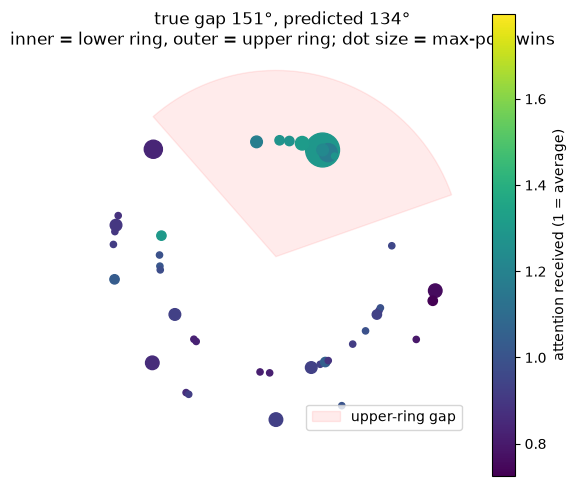

In [3]:
import matplotlib.pyplot as plt

def make_set_meta(rng):
    """Same as the benchmark's localized set, but keeps which ring each camera is in and where the gap is."""
    hole, start = rng.uniform(30, 150), rng.uniform(0, 360)
    n_lo, n_up = int(rng.integers(10, sg.NMAX // 2 + 1)), int(rng.integers(10, sg.NMAX // 2 + 1))
    p_lo, az_lo = sg.ring(rng, n_lo, 0, 15, 0.0, 0.0)            # full lower ring
    p_up, az_up = sg.ring(rng, n_up, 40, 55, hole, start)       # upper ring with the gap
    p, az = np.r_[p_lo, p_up], np.r_[az_lo, az_up]
    upper = np.r_[np.zeros(n_lo, bool), np.ones(n_up, bool)]
    p = (p @ sg.random_rotation(rng).T) * rng.uniform(0.2, 5) + rng.normal(0, 10, 3)   # arbitrary frame, as in training
    p = p - p.mean(0); p = p / np.median(np.linalg.norm(p, axis=1))
    return p, az, upper, start, hole, sg.largest_gap(az_up)

@torch.no_grad()
def inspect(model, p):
    """Run one camera set through the model and record who listens to whom and who wins the max-pool."""
    x = torch.tensor(p, dtype=torch.float32)[None]
    m = torch.ones(1, len(p), dtype=torch.bool)
    f = model.embed(x)
    a, w = model.attn(f, f, f, key_padding_mask=~m, need_weights=True, average_attn_weights=True)
    h = model.ff(f + a)
    pred = model.rho(h.max(1).values).item() * sg.SCALE
    received = w[0].mean(0).numpy() * len(p)                    # 1.0 = average attention
    wins = np.bincount(h[0].argmax(0).numpy(), minlength=len(p))  # max-pool slots won (out of 64)
    return pred, received, wins

attn.eval()
rng = np.random.default_rng(123)
p, az, upper, start, hole, true_gap = make_set_meta(rng)
pred, received, wins = inspect(attn, p)

# draw it top-down in the ring's own angles: lower ring inside, upper ring outside
r = np.where(upper, 1.4, 1.0); a = np.radians(az)
fig, ax = plt.subplots(figsize=(6, 6))
gap = np.radians(np.linspace(start, start + hole, 50))
ax.fill(np.r_[0, 1.6 * np.cos(gap), 0], np.r_[0, 1.6 * np.sin(gap), 0], color='red', alpha=0.08, label='upper-ring gap')
sc = ax.scatter(r * np.cos(a), r * np.sin(a), c=received, s=20 + 25 * wins, cmap='viridis')
plt.colorbar(sc, label='attention received (1 = average)')
ax.set_aspect('equal'); ax.axis('off'); ax.legend(loc='lower right')
ax.set_title(f'true gap {true_gap:.0f}°, predicted {pred:.0f}°\ninner = lower ring, outer = upper ring; dot size = max-pool wins')
plt.show()

In [4]:
def group_stats(n_sets=500, seed=7):
    """Average attention and max-pool wins for 4 groups of cameras, over many sets."""
    rng = np.random.default_rng(seed)
    groups = {'lower, under the gap': [], 'lower, elsewhere': [],
              'upper, near gap edge (<20°)': [], 'upper, elsewhere': []}
    def in_gap(az, start, hole): return ((az - start) % 360) < hole
    def to_edge(az, start, hole):
        d = lambda x, y: np.abs((x - y + 180) % 360 - 180)
        return np.minimum(d(az, start), d(az, start + hole))
    for _ in range(n_sets):
        p, az, upper, start, hole, _ = make_set_meta(rng)
        _, rec, wins = inspect(attn, p)
        g_lo_gap  = ~upper & in_gap(az, start, hole)
        g_lo_else = ~upper & ~in_gap(az, start, hole)
        g_up_edge = upper & (to_edge(az, start, hole) < 20)
        g_up_else = upper & (to_edge(az, start, hole) >= 20)
        for name, g in zip(groups, [g_lo_gap, g_lo_else, g_up_edge, g_up_else]):
            if g.any(): groups[name].append((rec[g].mean(), wins[g].mean()))
    print(f'{"camera group":30s} {"attention (1=avg)":>18s} {"max-pool wins":>14s}')
    for name, vals in groups.items():
        v = np.array(vals)
        print(f'{name:30s} {v[:,0].mean():18.2f} {v[:,1].mean():14.2f}')

group_stats()

camera group                    attention (1=avg)  max-pool wins
lower, under the gap                         1.44           3.59
lower, elsewhere                             1.09           2.04
upper, near gap edge (<20°)                  0.84           2.80
upper, elsewhere                             0.87           0.95


In [5]:
def in_gap(az, start, hole): return ((az - start) % 360) < hole

def renorm(p):
    p = p - p.mean(0); return p / np.median(np.linalg.norm(p, axis=1))   # same normalization as training

@torch.no_grad()
def predict(model, p):
    x = torch.tensor(p, dtype=torch.float32)[None]; m = torch.ones(1, len(p), dtype=torch.bool)
    return model(x, m).item() * sg.SCALE

def causal_test(model, n_sets=300, k=3, seed=11):
    rng = np.random.default_rng(seed); d_gap, d_else = [], []
    for _ in range(n_sets):
        p, az, upper, start, hole, _ = make_set_meta(rng)
        under = np.where(~upper & in_gap(az, start, hole))[0]
        other = np.where(~upper & ~in_gap(az, start, hole))[0]
        if len(under) < k or len(other) < k: continue
        base = predict(model, p)
        for pool, store in ((under, d_gap), (other, d_else)):
            keep = np.setdiff1d(np.arange(len(p)), rng.choice(pool, k, replace=False))
            store.append(predict(model, renorm(p[keep])) - base)
    print(f'remove {k} lower cams UNDER the gap : predicted gap changes by {np.mean(d_gap):+.1f}° (n={len(d_gap)})')
    print(f'remove {k} lower cams ELSEWHERE     : predicted gap changes by {np.mean(d_else):+.1f}°')

print('attention:'); causal_test(attn)
print('pointnet:');  causal_test(pnet)

attention:
remove 3 lower cams UNDER the gap : predicted gap changes by +3.4° (n=232)
remove 3 lower cams ELSEWHERE     : predicted gap changes by +1.1°
pointnet:
remove 3 lower cams UNDER the gap : predicted gap changes by +7.9° (n=232)
remove 3 lower cams ELSEWHERE     : predicted gap changes by +2.2°
